In [1]:
print("Hello! Welcome to my Generative AI project.")

import tensorflow as tf

print("TensorFlow version:", tf.__version__)

Hello! Welcome to my Generative AI project.
TensorFlow version: 2.21.0


In [1]:
import tensorflow as tf

print("Available GPUs:")
print(tf.config.list_physical_devices("GPU"))

Available GPUs:
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# 1. Dataset Loading and Exploration

This project compares Simple RNN, Bidirectional RNN,
LSTM, and GRU models for autoregressive text generation.

Dataset: Shakespeare's Complete Works
Source: Project Gutenberg


In [3]:
import requests

url = "https://www.gutenberg.org/ebooks/100.txt.utf-8"

response = requests.get(url, timeout=60)
response.raise_for_status()

text = response.content.decode("utf-8-sig")

print("Total characters:", len(text))
print("\nFirst 500 characters:\n")
print(text[:500])

Total characters: 5575099

First 500 characters:

The Project Gutenberg eBook of The Complete Works of William Shakespeare
    
This eBook is for the use of anyone anywhere in the United States and
most other parts of the world at no cost and with almost no restrictions
whatsoever. You may copy it, give it away or re-use it under the terms
of the Project Gutenberg License included with this eBook or online
at www.gutenberg.org. If you are not located in the United States,
you will have to check the laws of the country where you are locat


In [4]:
print("Dataset Statistics")
print("------------------")

print("Total characters:", len(text))
print("Total words:", len(text.split()))
print("Total lines:", len(text.splitlines()))

print("\nSample text:\n")
print(text[10000:11000])

Dataset Statistics
------------------
Total characters: 5575099
Total words: 966506
Total lines: 196398

Sample text:

nopy the herd
And summer’s green all girded up in sheaves
Borne on the bier with white and bristly beard:
Then of thy beauty do I question make
That thou among the wastes of time must go,
Since sweets and beauties do themselves forsake,
And die as fast as they see others grow,
  And nothing ’gainst Time’s scythe can make defence
  Save breed to brave him, when he takes thee hence.


                    13

O that you were your self, but love you are
No longer yours, than you yourself here live,
Against this coming end you should prepare,
And your sweet semblance to some other give.
So should that beauty which you hold in lease
Find no determination, then you were
Yourself again after yourself’s decease,
When your sweet issue your sweet form should bear.
Who lets so fair a house fall to decay,
Which husbandry in honour might uphold,
Against the stormy gusts of winter’s 

# 2. Text Preprocessing

The raw Shakespeare dataset is cleaned and converted
into a suitable format for word-level autoregressive
text generation.

In [49]:
import re

# Remove the Project Gutenberg header
start_marker = "*** START OF THE PROJECT GUTENBERG EBOOK"
end_marker = "*** END OF THE PROJECT GUTENBERG EBOOK"

start = text.find(start_marker)
end = text.find(end_marker)

if start == -1 or end == -1:
    raise ValueError("Project Gutenberg markers not found")

text_body = text[text.find("\n", start) + 1:end]

# Find the beginning of the actual Shakespeare text
matches = list(re.finditer(r"THE SONNETS", text_body))

if len(matches) < 2:
    raise ValueError("Could not locate the Shakespeare sonnets")

actual_text_start = matches[1].start()

# Select 500,000 characters
text_subset = text_body[
    actual_text_start:actual_text_start + 500000
]

# Clean the text
cleaned_text = text_subset.lower()
cleaned_text = re.sub(r"[^a-z\s']", " ", cleaned_text)
cleaned_text = re.sub(r"\s+", " ", cleaned_text).strip()

print("Cleaned characters:", len(cleaned_text))
print("Cleaned words:", len(cleaned_text.split()))
print("\nSample:")
print(cleaned_text[:500])

Cleaned characters: 451680
Cleaned words: 88719

Sample:
the sonnets from fairest creatures we desire increase that thereby beauty s rose might never die but as the riper should by time decease his tender heir might bear his memory but thou contracted to thine own bright eyes feed st thy light s flame with self substantial fuel making a famine where abundance lies thyself thy foe to thy sweet self too cruel thou that art now the world s fresh ornament and only herald to the gaudy spring within thine own bud buriest thy content and tender churl mak st 


In [14]:
# Split the text chronologically by words
words = cleaned_text.split()

train_end = int(0.8 * len(words))
val_end = int(0.9 * len(words))

train_words = words[:train_end]
val_words = words[train_end:val_end]
test_words = words[val_end:]

print("Training words:", len(train_words))
print("Validation words:", len(val_words))
print("Testing words:", len(test_words))

Training words: 70975
Validation words: 8872
Testing words: 8872


In [15]:
from tensorflow.keras.preprocessing.text import Tokenizer

# Keep the 5000 most frequent words
tokenizer = Tokenizer(
    num_words=5000,
    oov_token="<OOV>",
    filters=""
)

# Learn vocabulary from training data only
tokenizer.fit_on_texts([" ".join(train_words)])

# Convert each split into integer sequences
train_tokens = tokenizer.texts_to_sequences(
    [" ".join(train_words)]
)[0]

val_tokens = tokenizer.texts_to_sequences(
    [" ".join(val_words)]
)[0]

test_tokens = tokenizer.texts_to_sequences(
    [" ".join(test_words)]
)[0]

vocab_size = min(5000, len(tokenizer.word_index) + 1)

print("Vocabulary size:", vocab_size)
print("First 20 training tokens:", train_tokens[:20])
print("First 20 words:", train_words[:20])

Vocabulary size: 5000
First 20 training tokens: [2, 3313, 53, 1225, 1226, 44, 448, 858, 10, 2339, 144, 13, 780, 150, 140, 238, 21, 31, 2, 2340]
First 20 words: ['the', 'sonnets', 'from', 'fairest', 'creatures', 'we', 'desire', 'increase', 'that', 'thereby', 'beauty', 's', 'rose', 'might', 'never', 'die', 'but', 'as', 'the', 'riper']


# 3. Creating Input–Target Sequences

A sliding window is used to create fixed-length input
sequences and their corresponding next-word targets.

Sequence length = 20 words.

In [16]:
import numpy as np

# Number of previous words used to predict the next word
sequence_length = 20

def create_sequences(tokens, sequence_length):
    X = []
    y = []

    for i in range(sequence_length, len(tokens)):
        X.append(tokens[i-sequence_length:i])
        y.append(tokens[i])

    return np.array(X, dtype=np.int32), np.array(y, dtype=np.int32)


# Create sequences separately for each dataset split
X_train, y_train = create_sequences(train_tokens, sequence_length)
X_val, y_val = create_sequences(val_tokens, sequence_length)
X_test, y_test = create_sequences(test_tokens, sequence_length)

print("Training input shape:", X_train.shape)
print("Training target shape:", y_train.shape)

print("Validation input shape:", X_val.shape)
print("Testing input shape:", X_test.shape)

Training input shape: (70955, 20)
Training target shape: (70955,)
Validation input shape: (8852, 20)
Testing input shape: (8852, 20)


In [17]:
# Display first training example
print("Input token IDs:")
print(X_train[0])

print("\nTarget token ID:")
print(y_train[0])

# Convert token IDs back into words
index_to_word = tokenizer.index_word

input_words = [
    index_to_word.get(int(token), "<OOV>")
    for token in X_train[0]
]

target_word = index_to_word.get(int(y_train[0]), "<OOV>")

print("\nInput words:")
print(" ".join(input_words))

print("\nExpected next word:")
print(target_word)

Input token IDs:
[   2 3313   53 1225 1226   44  448  858   10 2339  144   13  780  150
  140  238   21   31    2 2340]

Target token ID:
86

Input words:
the sonnets from fairest creatures we desire increase that thereby beauty s rose might never die but as the riper

Expected next word:
should


# 4. Building the Deep Learning Models

Four recurrent neural network architectures are
implemented for next-word prediction:

1. Simple RNN
2. Bidirectional RNN
3. LSTM
4. GRU

In [20]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Embedding,
    SimpleRNN,
    Bidirectional,
    LSTM,
    GRU,
    Dense
)

# Set random seed for reproducibility
tf.keras.utils.set_random_seed(42)

# Common model settings
embedding_dim = 64
hidden_units = 128

print("TensorFlow version:", tf.__version__)
print("Vocabulary size:", vocab_size)
print("Sequence length:", sequence_length)

TensorFlow version: 2.21.0
Vocabulary size: 5000
Sequence length: 20


In [21]:
rnn_model = Sequential([
    Input(shape=(sequence_length,)),

    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim
    ),

    SimpleRNN(hidden_units),

    Dense(vocab_size, activation="softmax")
])

rnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 20, 64)         │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 128)            │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5000)           │       645,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 989,704 (3.78 MB)

 Trainable params: 989,704 (3.78 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:
birnn_model = Sequential([
    Input(shape=(sequence_length,)),

    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim
    ),

    Bidirectional(
        SimpleRNN(hidden_units)
    ),

    Dense(vocab_size, activation="softmax")
])

birnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 20, 64)         │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 256)            │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5000)           │     1,285,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,654,408 (6.31 MB)

 Trainable params: 1,654,408 (6.31 MB)

 Non-trainable params: 0 (0.00 B)

In [23]:
lstm_model = Sequential([
    Input(shape=(sequence_length,)),

    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim
    ),

    LSTM(hidden_units),

    Dense(vocab_size, activation="softmax")
])

lstm_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 20, 64)         │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5000)           │       645,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,063,816 (4.06 MB)

 Trainable params: 1,063,816 (4.06 MB)

 Non-trainable params: 0 (0.00 B)

In [24]:
gru_model = Sequential([
    Input(shape=(sequence_length,)),

    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim
    ),

    GRU(hidden_units),

    Dense(vocab_size, activation="softmax")
])

gru_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 20, 64)         │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 128)            │        74,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5000)           │       645,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,039,496 (3.97 MB)

 Trainable params: 1,039,496 (3.97 MB)

 Non-trainable params: 0 (0.00 B)

In [25]:
models = {
    "Simple RNN": rnn_model,
    "Bidirectional RNN": birnn_model,
    "LSTM": lstm_model,
    "GRU": gru_model
}

for name, model in models.items():

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    print(f"{name} compiled successfully!")

Simple RNN compiled successfully!
Bidirectional RNN compiled successfully!
LSTM compiled successfully!
GRU compiled successfully!


In [26]:
print("Model Parameter Comparison")
print("-" * 45)

for name, model in models.items():
    print(f"{name}: {model.count_params():,} parameters")

Model Parameter Comparison
---------------------------------------------
Simple RNN: 989,704 parameters
Bidirectional RNN: 1,654,408 parameters
LSTM: 1,063,816 parameters
GRU: 1,039,496 parameters


# 5. Model Training

All four models are trained using the same dataset,
batch size, maximum epochs, optimizer and early-stopping
configuration to enable a comparable evaluation.

In [27]:
from tensorflow.keras.callbacks import EarlyStopping
import time
import pandas as pd

# Common training settings
epochs = 10
batch_size = 128

# Store training results
histories = {}
training_times = {}

print("Training configuration ready!")
print("Epochs:", epochs)
print("Batch size:", batch_size)
print("Training examples:", len(X_train))
print("Validation examples:", len(X_val))

Training configuration ready!
Epochs: 10
Batch size: 128
Training examples: 70955
Validation examples: 8852


In [28]:
for name, model in models.items():

    print("\n" + "=" * 50)
    print("Training:", name)
    print("=" * 50)

    # Fresh early stopping for each model
    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )

    # Record start time
    start_time = time.time()

    # Train model
    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=batch_size,
        callbacks=[early_stopping],
        verbose=1
    )

    # Calculate training time
    elapsed_time = time.time() - start_time

    # Store results
    histories[name] = history.history
    training_times[name] = elapsed_time

    print(f"\n{name} training completed!")
    print(f"Training time: {elapsed_time:.2f} seconds")


Training: Simple RNN
Epoch 1/10
555/555 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.0351 - loss: 6.5367 - val_accuracy: 0.0784 - val_loss: 5.7948
Epoch 2/10
555/555 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.0548 - loss: 6.1005 - val_accuracy: 0.0957 - val_loss: 5.6155
Epoch 3/10
555/555 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.0748 - loss: 5.8126 - val_accuracy: 0.1011 - val_loss: 5.5295
Epoch 4/10
555/555 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.0871 - loss: 5.5772 - val_accuracy: 0.1016 - val_loss: 5.5080
Epoch 5/10
555/555 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.0968 - loss: 5.3790 - val_accuracy: 0.1002 - val_loss: 5.5226
Epoch 6/10
555/555 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.1060 - loss: 5.2094 - val_accuracy: 0.1000 - val_loss: 5.5554
Epoch 7/10
555/555 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.1140 - loss: 5.0570 - val_accuracy: 0.1053 - val_loss: 5.5624

Simple RNN training completed!
Training time: 25.78 seconds

Training: Bidirect

In [29]:
training_summary = []

for name in models.keys():

    history = histories[name]

    training_summary.append({
        "Model": name,
        "Epochs Trained": len(history["loss"]),
        "Best Validation Loss": min(history["val_loss"]),
        "Best Validation Accuracy": max(history["val_accuracy"]),
        "Training Time (s)": training_times[name]
    })

training_df = pd.DataFrame(training_summary)

display(training_df.round(4))

,Model,Epochs Trained,Best Validation Loss,Best Validation Accuracy,Training Time (s)
0,Simple RNN,7,5.5080,0.1053,25.7768
1,Bidirectional RNN,7,5.5659,0.1031,31.4588
2,LSTM,10,5.4568,0.1158,45.6306
3,GRU,8,5.4171,0.1185,34.6702


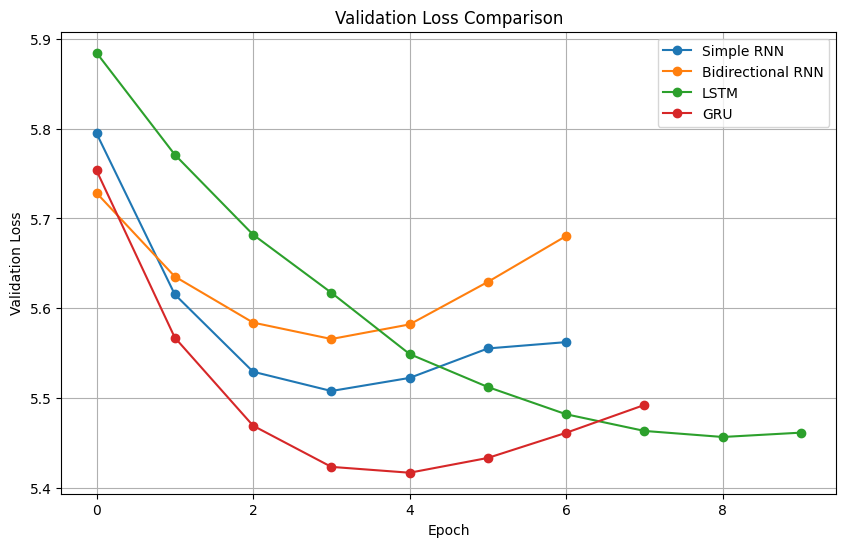

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for name, history in histories.items():
    plt.plot(
        history["val_loss"],
        marker="o",
        label=name
    )

plt.title("Validation Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

# 6. Model Evaluation

The four trained models are evaluated on unseen test
data using loss, accuracy, and perplexity.

In [31]:
import numpy as np
import pandas as pd

evaluation_results = []

for name, model in models.items():

    print(f"Evaluating {name}...")

    test_loss, test_accuracy = model.evaluate(
        X_test,
        y_test,
        batch_size=128,
        verbose=0
    )

    perplexity = np.exp(test_loss)

    evaluation_results.append({
        "Model": name,
        "Test Loss": test_loss,
        "Perplexity": perplexity,
        "Test Accuracy": test_accuracy,
        "Training Time (s)": training_times[name]
    })

evaluation_df = pd.DataFrame(evaluation_results)

display(evaluation_df.round(4))

Evaluating Simple RNN...
Evaluating Bidirectional RNN...
Evaluating LSTM...
Evaluating GRU...


,Model,Test Loss,Perplexity,Test Accuracy,Training Time (s)
0,Simple RNN,5.4827,240.4953,0.1108,25.7768
1,Bidirectional RNN,5.5420,255.1772,0.1069,31.4588
2,LSTM,5.4728,238.1209,0.1165,45.6306
3,GRU,5.4204,225.9705,0.1214,34.6702


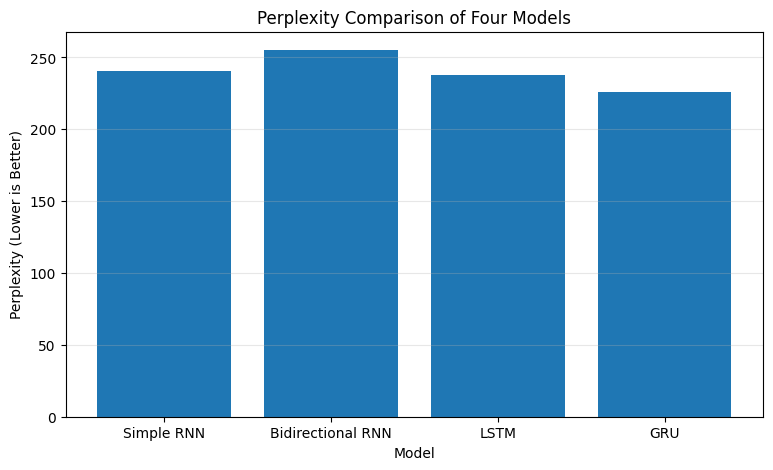

In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    evaluation_df["Model"],
    evaluation_df["Perplexity"]
)

plt.title("Perplexity Comparison of Four Models")
plt.xlabel("Model")
plt.ylabel("Perplexity (Lower is Better)")

plt.grid(axis="y", alpha=0.3)
plt.show()

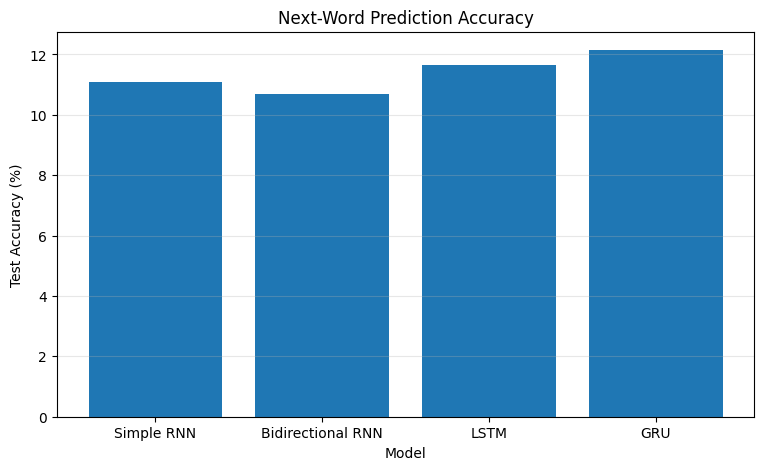

In [33]:
plt.figure(figsize=(9, 5))

plt.bar(
    evaluation_df["Model"],
    evaluation_df["Test Accuracy"] * 100
)

plt.title("Next-Word Prediction Accuracy")
plt.xlabel("Model")
plt.ylabel("Test Accuracy (%)")

plt.grid(axis="y", alpha=0.3)
plt.show()

In [34]:
import os

os.makedirs("saved_models", exist_ok=True)

for name, model in models.items():

    filename = name.lower().replace(" ", "_") + ".keras"

    model.save("saved_models/" + filename)

    print(f"Saved: {filename}")

Saved: simple_rnn.keras
Saved: bidirectional_rnn.keras
Saved: lstm.keras
Saved: gru.keras


In [35]:
import pickle

with open("saved_models/tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

print("Tokenizer saved successfully!")

Tokenizer saved successfully!


# 7. Autoregressive Text Generation

The trained models generate text sequentially from
the same seed sequences using temperature sampling.

In [36]:
import numpy as np
import tensorflow as tf

def generate_text(model, seed_text, num_words=30,
                  temperature=1.0, random_seed=42):

    if temperature <= 0:
        raise ValueError("Temperature must be greater than zero")

    rng = np.random.default_rng(random_seed)

    generated_words = seed_text.lower().split()

    for _ in range(num_words):

        # Convert current text into token IDs
        token_list = tokenizer.texts_to_sequences(
            [" ".join(generated_words)]
        )[0]

        # Use only the most recent 20 tokens
        token_list = token_list[-sequence_length:]

        # Pad shorter seed sequences with zeros
        padded_sequence = tf.keras.preprocessing.sequence.pad_sequences(
            [token_list],
            maxlen=sequence_length,
            padding="pre"
        )

        # Predict next-word probabilities
        predictions = model(
            padded_sequence, training=False
        ).numpy()[0]

        # Apply temperature to the probabilities
        logits = np.log(np.maximum(predictions, 1e-10))
        logits = logits / temperature

        # Numerically stable softmax
        logits = logits - np.max(logits)
        probabilities = np.exp(logits)
        probabilities = probabilities / np.sum(probabilities)

        # Avoid selecting padding and OOV tokens
        probabilities[0] = 0
        probabilities[1] = 0
        probabilities = probabilities / probabilities.sum()

        # Sample next word
        next_token = rng.choice(
            len(probabilities),
            p=probabilities
        )

        next_word = tokenizer.index_word.get(
            int(next_token), ""
        )

        if not next_word:
            break

        generated_words.append(next_word)

    return " ".join(generated_words)

print("Text generation function created successfully!")

Text generation function created successfully!


In [37]:
seed_text = "from fairest creatures we desire"

print("Seed:", seed_text)
print("=" * 70)

for name, model in models.items():

    generated = generate_text(
        model,
        seed_text,
        num_words=30,
        temperature=1.0,
        random_seed=42
    )

    print(f"\n{name}:")
    print(generated)
    print("-" * 70)

Seed: from fairest creatures we desire

Simple RNN:
from fairest creatures we desire their disgrace dercetus gentle a crop still bertram i am it pay so drown that our brave shall ended now boy you cried hence how s life and i thine
----------------------------------------------------------------------

Bidirectional RNN:
from fairest creatures we desire now madam none then to trumpet far dolabella i ll her learning first friend he s virtue to soothsayer lord at his transgression proceed go it all the man or
----------------------------------------------------------------------

LSTM:
from fairest creatures we desire well helena why were i punish thee noble love be good cargo another egyptian love that then i lend thee put his ruth hold t in her to be write
----------------------------------------------------------------------

GRU:
from fairest creatures we desire where all young brief and grafted away back and leave me wither she english when my memory i perceive an distraction that j

In [38]:
temperatures = [0.5, 1.0, 1.5]

seed_text = "from fairest creatures we desire"

generation_results = []

for name, model in models.items():

    for temp in temperatures:

        generated = generate_text(
            model,
            seed_text,
            num_words=30,
            temperature=temp,
            random_seed=42
        )

        generation_results.append({
            "Model": name,
            "Temperature": temp,
            "Generated Text": generated
        })

        print(f"\nModel: {name}")
        print(f"Temperature: {temp}")
        print(generated)
        print("-" * 70)


Model: Simple RNN
Temperature: 0.5
from fairest creatures we desire thou art st with the article of my heart and that we do be in the sweet and where he shall be fall for thy love and i have not
----------------------------------------------------------------------

Model: Simple RNN
Temperature: 1.0
from fairest creatures we desire their disgrace dercetus gentle a crop still bertram i am it pay so drown that our brave shall ended now boy you cried hence how s life and i thine
----------------------------------------------------------------------

Model: Simple RNN
Temperature: 1.5
from fairest creatures we desire heat steal trusting trust my helped politic narbon that out if pearl fought fated pass it three love soil nile earth put confidence shower gallus may lead to good copy
----------------------------------------------------------------------

Model: Bidirectional RNN
Temperature: 0.5
from fairest creatures we desire me you are not i think you sir i am you here you ll not a room

In [39]:
# Select three 20-word seed sequences from test data
seed_sequences = []

for i in [100, 1000, 3000]:

    seed_tokens = X_test[i]

    seed_words = [
        tokenizer.index_word.get(int(token), "<OOV>")
        for token in seed_tokens
    ]

    seed_sequences.append(" ".join(seed_words))

# Display selected seeds
for i, seed in enumerate(seed_sequences, 1):
    print(f"\nSeed {i}:")
    print(seed)


Seed 1:
of time if ever you have looked on better days if ever been where <OOV> have <OOV> to <OOV> if

Seed 2:
my verse in witness of my love and thou thrice crowned queen of night survey with thy chaste eye from

Seed 3:
i do desire we may be better strangers jaques i pray you mar no more trees with <OOV> love songs


In [40]:
temperatures = [0.5, 1.0, 1.5]

generation_results = []

for seed_number, seed in enumerate(seed_sequences, 1):

    for name, model in models.items():

        for temp in temperatures:

            generated = generate_text(
                model,
                seed,
                num_words=30,
                temperature=temp,
                random_seed=42
            )

            generation_results.append({
                "Seed": seed_number,
                "Model": name,
                "Temperature": temp,
                "Generated Text": generated
            })

generation_df = pd.DataFrame(generation_results)

display(generation_df)

,Seed,Model,Temperature,Generated Text
0,1,Simple RNN,0.5,of time if ever you have looked on better days...
1,1,Simple RNN,1.0,of time if ever you have looked on better days...
2,1,Simple RNN,1.5,of time if ever you have looked on better days...
3,1,Bidirectional RNN,0.5,of time if ever you have looked on better days...
4,1,Bidirectional RNN,1.0,of time if ever you have looked on better days...
5,1,Bidirectional RNN,1.5,of time if ever you have looked on better days...
6,1,LSTM,0.5,of time if ever you have looked on better days...
7,1,LSTM,1.0,of time if ever you have looked on better days...
8,1,LSTM,1.5,of time if ever you have looked on better days...
9,1,GRU,0.5,of time if ever you have looked on better days...


In [41]:
generation_df.to_csv(
    "generated_text_samples.csv",
    index=False
)

print("Generated samples saved successfully!")

Generated samples saved successfully!


# 8. Qualitative Text Analysis

Generated text is analyzed for diversity, repetition,
coherence, and contextual consistency.

In [42]:
def calculate_text_metrics(generated_text, seed_length=20):

    # Evaluate only newly generated words
    words = generated_text.split()[seed_length:]

    if not words:
        return 0, 0, 0

    # Distinct-1: unique word ratio
    distinct_1 = len(set(words)) / len(words)

    # Distinct-2: unique bigram ratio
    bigrams = list(zip(words[:-1], words[1:]))

    distinct_2 = (
        len(set(bigrams)) / len(bigrams)
        if bigrams else 0
    )

    # Repeated bigram proportion
    repetition = 1 - distinct_2

    return distinct_1, distinct_2, repetition


# Calculate metrics for all 36 generated samples
generation_df[
    ["Distinct-1", "Distinct-2", "Repetition"]
] = generation_df["Generated Text"].apply(
    lambda text: pd.Series(calculate_text_metrics(text))
)

display(
    generation_df[
        ["Seed", "Model", "Temperature",
         "Distinct-1", "Distinct-2", "Repetition"]
    ].round(4)
)

,Seed,Model,Temperature,Distinct-1,Distinct-2,Repetition
0,1,Simple RNN,0.5,0.8000,0.9655,0.0345
1,1,Simple RNN,1.0,0.9333,1.0000,0.0000
2,1,Simple RNN,1.5,1.0000,1.0000,0.0000
3,1,Bidirectional RNN,0.5,0.8333,1.0000,0.0000
4,1,Bidirectional RNN,1.0,0.9333,1.0000,0.0000
5,1,Bidirectional RNN,1.5,1.0000,1.0000,0.0000
6,1,LSTM,0.5,0.7667,1.0000,0.0000
7,1,LSTM,1.0,0.9667,1.0000,0.0000
8,1,LSTM,1.5,1.0000,1.0000,0.0000
9,1,GRU,0.5,0.7333,0.8966,0.1034


In [43]:
quality_summary = (
    generation_df
    .groupby(["Model", "Temperature"])
    [["Distinct-1", "Distinct-2", "Repetition"]]
    .mean()
    .reset_index()
)

display(quality_summary.round(4))

,Model,Temperature,Distinct-1,Distinct-2,Repetition
0,Bidirectional RNN,0.5,0.7667,0.9425,0.0575
1,Bidirectional RNN,1.0,0.9667,1.0000,0.0000
2,Bidirectional RNN,1.5,1.0000,1.0000,0.0000
3,GRU,0.5,0.7778,0.9655,0.0345
4,GRU,1.0,0.9333,1.0000,0.0000
5,GRU,1.5,1.0000,1.0000,0.0000
6,LSTM,0.5,0.7889,1.0000,0.0000
7,LSTM,1.0,0.9556,1.0000,0.0000
8,LSTM,1.5,0.9667,1.0000,0.0000
9,Simple RNN,0.5,0.7889,0.9425,0.0575


In [44]:
for _, row in generation_df.iterrows():

    if row["Seed"] == 1:

        print("\nModel:", row["Model"])
        print("Temperature:", row["Temperature"])

        continuation = " ".join(
            row["Generated Text"].split()[20:]
        )

        print("Generated continuation:")
        print(continuation)
        print("-" * 70)


Model: Simple RNN
Temperature: 0.5
Generated continuation:
thou art st thou be nothing that thou be st my tongue in our own heart to the hour of a man should know your good lord and and my
----------------------------------------------------------------------

Model: Simple RNN
Temperature: 1.0
Generated continuation:
we was prey thee i inherit live charmian of that he partly words second own art if and promise more weak that punish again stand a writ and s took
----------------------------------------------------------------------

Model: Simple RNN
Temperature: 1.5
Generated continuation:
didst call patent weight to shoes strike kisses not whether may ercharged lend decrees till thy ythee have approves stands mystery all enlighten promising uncertain last told the wars lends
----------------------------------------------------------------------

Model: Bidirectional RNN
Temperature: 0.5
Generated continuation:
you shall be all the lower hand s no great his worm s camp scene iii alex

In [45]:
generation_df.to_csv(
    "generated_text_samples.csv",
    index=False
)

quality_summary.to_csv(
    "text_quality_comparison.csv",
    index=False
)

evaluation_df.to_csv(
    "model_evaluation_results.csv",
    index=False
)

training_df.to_csv(
    "training_summary.csv",
    index=False
)

print("All evaluation files saved successfully!")

All evaluation files saved successfully!


# 9. Results and Conclusion

## Quantitative Model Comparison

Four recurrent neural network architectures were trained
on a Shakespeare text corpus for word-level autoregressive
text generation.

The GRU model achieved the best test performance:

- Test loss: 5.4204
- Perplexity: 225.9705
- Test accuracy: 12.14%
- Training time: 34.67 seconds

The Simple RNN was the fastest model, requiring 25.78
seconds, but achieved lower prediction accuracy.

LSTM performed competitively but required the longest
training time.

Bidirectional RNN had the highest parameter count and
the weakest test performance in this experiment.

## Temperature Analysis

Three sampling temperatures were evaluated: 0.5, 1.0,
and 1.5.

At temperature 0.5, generated text used more common
words and showed lower lexical diversity.

At temperature 1.0, the outputs generally exhibited
greater vocabulary variation.

At temperature 1.5, lexical diversity increased further,
but the generated text often became less coherent.

## Limitations

The models were trained using a relatively small corpus,
a restricted vocabulary of 5,000 words, and a fixed
context length of 20 words.

Generated text frequently contained grammatical errors
and inconsistent context.

## Conclusion

GRU was the most effective model quantitatively for
this dataset and experimental configuration, achieving
the lowest test perplexity and highest next-word accuracy.

However, none of the models consistently generated
fully coherent passages. Better results may require
larger training datasets, improved preprocessing,
and further hyperparameter tuning.

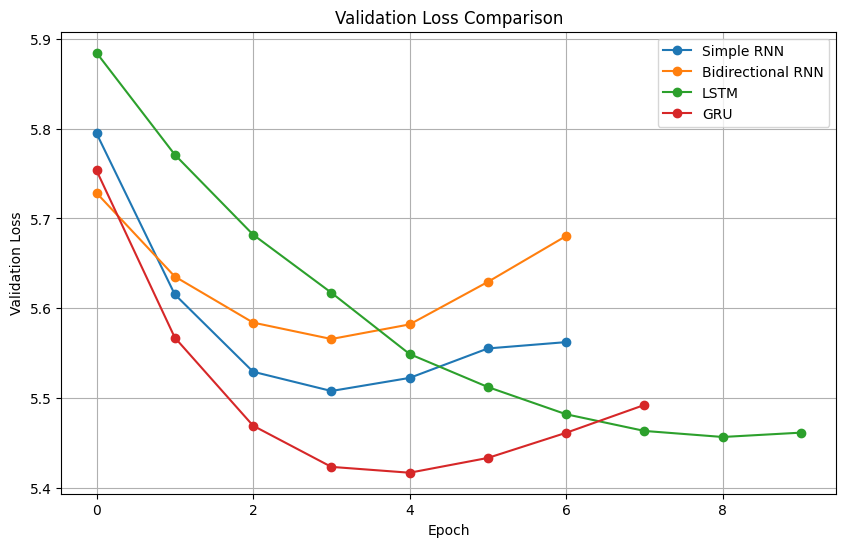

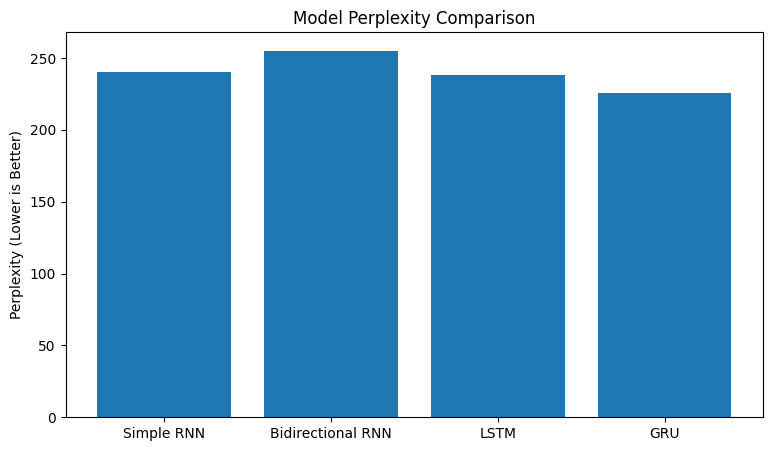

In [46]:
import matplotlib.pyplot as plt

# Save validation loss comparison
plt.figure(figsize=(10, 6))

for name, history in histories.items():
    plt.plot(history["val_loss"], marker="o", label=name)

plt.title("Validation Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid(True)

plt.savefig("validation_loss_comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()


# Save perplexity comparison
plt.figure(figsize=(9, 5))

plt.bar(evaluation_df["Model"],
        evaluation_df["Perplexity"])

plt.title("Model Perplexity Comparison")
plt.ylabel("Perplexity (Lower is Better)")

plt.savefig("perplexity_comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [47]:
import shutil
import os

# Make sure the models were saved earlier
assert os.path.isdir("saved_models"), "Run the model-saving cell first."

# Create results directory
os.makedirs("results", exist_ok=True)

files_to_save = [
    "generated_text_samples.csv",
    "text_quality_comparison.csv",
    "model_evaluation_results.csv",
    "training_summary.csv",
    "validation_loss_comparison.png",
    "perplexity_comparison.png"
]

for filename in files_to_save:
    if os.path.exists(filename):
        shutil.copy(filename, "results/" + filename)
    else:
        print("Missing file:", filename)

# Create ZIP archive
shutil.make_archive(
    "FGAI_Assignment2_Backup",
    "zip",
    ".",
    "results"
)

print("Backup ZIP created successfully!")

Backup ZIP created successfully!


In [48]:
import shutil
from google.colab import files

shutil.make_archive(
    "FGAI_Trained_Models",
    "zip",
    "saved_models"
)

files.download("FGAI_Trained_Models.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>